# Defense results (P3): poisoning and robustness in streaming classifiers

All numbers come from the PaySim attacked samples built by `scripts/make_attacked_sample.py`
(seed 0, `sample_frac` 0.1, stream = steps below 600, clean held-out test set = steps 600 and later).
Each attacked file is replayed window by window (24 steps per window) through `defend()`, and the
learner (`OnlineLearner`) trains only on the accepted records. **One seed only**: seeds 1 and 2 are
pending, so treat differences of a few hundredths as noise.

How the tables were produced (all offline; `is_poisoned` is stripped before every `defend` call):

```
python scripts/tune_defense.py --subgroups --out results/final_default.csv
python scripts/eval_utility.py --budgets 0.05 --out results/utility_b005.csv
python scripts/eval_utility.py --budgets 0.2  --out results/utility_b02.csv
python scripts/collect_results.py        # -> results/summary/*.csv (committed)
```

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

S = Path("../results/summary") if Path("../results/summary").exists() else Path("results/summary")
det = pd.read_csv(S / "detection_seed0.csv")
util = pd.read_csv(S / "utility_seed0.csv")
abl = pd.read_csv(S / "ablation_seed0.csv")

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True})
print(len(det), "detection rows,", len(util), "utility rows,", len(abl), "ablation rows")

27 detection rows, 27 utility rows, 78 ablation rows


## 1. Does the defense protect the learner?

PR-AUC on the clean test set after the whole stream. The learner trained on a clean stream scores 0.999
(PaySim fraud is easy to separate), so most attacks cannot hurt much. The ones that can are the label
floods (`random_flip` with uniform or low-and-slow timing) and `feature_noise` spread over time.

In [2]:
u = util.copy()
u["case"] = u["attack"] + " " + u["budget"].astype(str) + " " + u["timing"].str.replace("_", "-")
tbl = u[["case", "pr_auc_clean", "pr_auc_no_defense", "pr_auc_defended", "recall_no_defense", "recall_defended"]]
tbl = tbl.sort_values("pr_auc_no_defense").round(3).reset_index(drop=True)
tbl

,case,pr_auc_clean,pr_auc_no_defense,pr_auc_defended,recall_no_defense,recall_defended
0,random_flip 0.2 uniform,0.999,0.011,0.977,0.931,0.977
1,random_flip 0.2 low-and-slow,0.999,0.014,0.952,1.000,0.983
2,random_flip 0.05 uniform,0.999,0.069,0.976,0.832,0.977
3,random_flip 0.05 low-and-slow,0.999,0.497,0.918,0.994,0.977
4,feature_noise 0.2 uniform,0.999,0.649,0.988,0.867,0.971
5,feature_shift 0.05 uniform,0.999,0.988,0.987,0.971,0.977
6,targeted_flip 0.2 uniform,0.999,0.988,0.987,0.983,0.983
7,feature_noise 0.2 burst,0.999,0.991,0.985,0.983,0.977
8,feature_shift 0.2 uniform,0.999,0.993,0.987,0.983,0.971
9,feature_noise 0.05 uniform,0.999,0.993,0.990,0.983,0.977


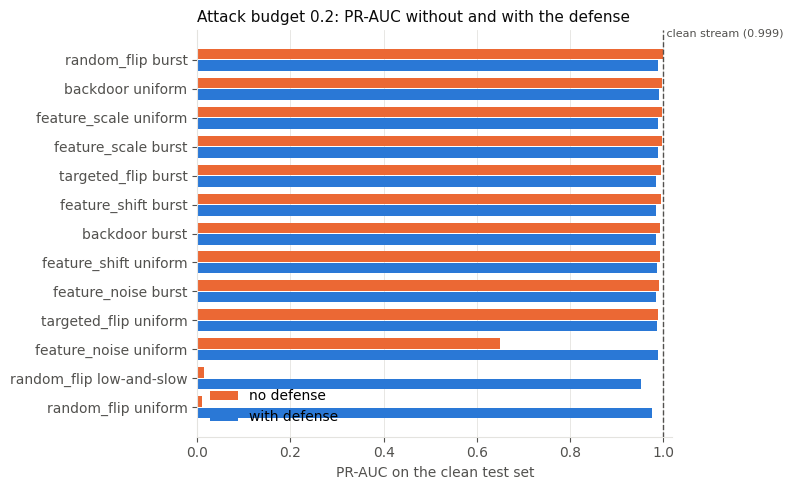

In [3]:
d = u[u["budget"] == 0.2].sort_values("pr_auc_no_defense", ascending=False)
labels = (d["attack"] + " " + d["timing"].str.replace("_", "-")).tolist()
y = np.arange(len(d))
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(y - 0.2, d["pr_auc_no_defense"], height=0.36, color=ORANGE, label="no defense")
ax.barh(y + 0.2, d["pr_auc_defended"], height=0.36, color=BLUE, label="with defense")
ax.axvline(d["pr_auc_clean"].iloc[0], color=MUTED, lw=1, ls="--")
ax.text(d["pr_auc_clean"].iloc[0], -0.9, " clean stream (0.999)", color=MUTED, fontsize=8, va="center")
ax.set_yticks(y); ax.set_yticklabels(labels); ax.invert_yaxis()
ax.set_xlim(0, 1.02); ax.set_xlabel("PR-AUC on the clean test set")
ax.set_title("Attack budget 0.2: PR-AUC without and with the defense", loc="left", color=INK, fontsize=11)
ax.legend(frameon=False, loc="lower left"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Reading it.** Without a defense, uniform and low-and-slow label flips drive PR-AUC to about 0.01, and
uniform `feature_noise` to 0.65. With the defense, all of them are back above 0.95. Where the attack barely
hurts (PR-AUC 0.99 or more undefended) the defense costs about 0.01, because it sometimes quarantines real
frauds.

## 2. Which detector does what? (ablation, budget 0.2)

Mean detection recall over the poisoned records (uniform and burst files).

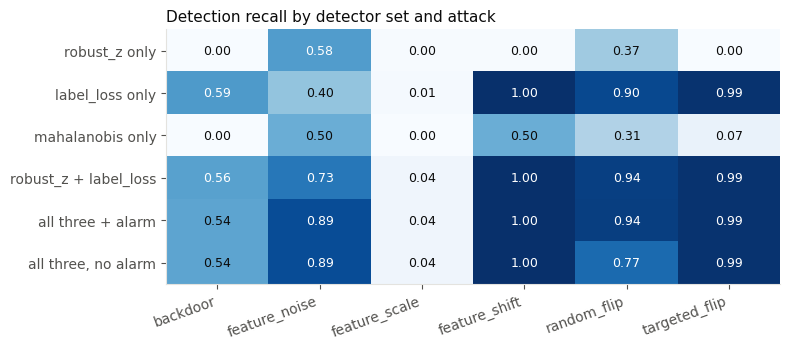

,clean_records_lost,real_frauds_lost
variant,,
robust_z only,0.0001,0.0075
label_loss only,0.0000,0.0135
mahalanobis only,0.0002,0.0000
robust_z + label_loss,0.0001,0.0475
all three + alarm,0.0004,0.0513
"all three, no alarm",0.0008,0.2337


In [4]:
order = ["robust_z only", "label_loss only", "mahalanobis only", "robust_z + label_loss", "all three + alarm", "all three, no alarm"]
rec = abl.groupby(["variant", "attack"]).recall.mean().unstack().loc[order]
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(rec.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(rec.shape[1])); ax.set_xticklabels(rec.columns, rotation=20, ha="right")
ax.set_yticks(range(rec.shape[0])); ax.set_yticklabels(rec.index); ax.grid(False)
for i in range(rec.shape[0]):
    for j in range(rec.shape[1]):
        v = rec.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.55 else INK, fontsize=9)
ax.set_title("Detection recall by detector set and attack", loc="left", color=INK, fontsize=11)
plt.tight_layout(); plt.show()
cost = abl.groupby("variant").agg(clean_records_lost=("clean_loss", "mean"), real_frauds_lost=("clean_fraud_loss", "mean")).loc[order].round(4)
cost

**Reading it.** No single detector wins everywhere. `label_loss` does most of the work on label attacks and,
unexpectedly, `feature_shift`. `robust_z` is weak alone (its fraud-class reference is built from only 24 to 50
fraud rows). Mahalanobis adds mostly on `feature_noise`. The fraud-label alarm matters most for `random_flip`:
without it, 23% of the real frauds are quarantined and recall drops from 0.94 to 0.77.

## 3. Does the defense treat clean records fairly?

Share of **clean** records quarantined, by transaction type and by amount quartile (mean over all attacked files).
A defense that mostly drops one kind of legitimate record would be a responsible-AI problem even if the overall
rate is low.

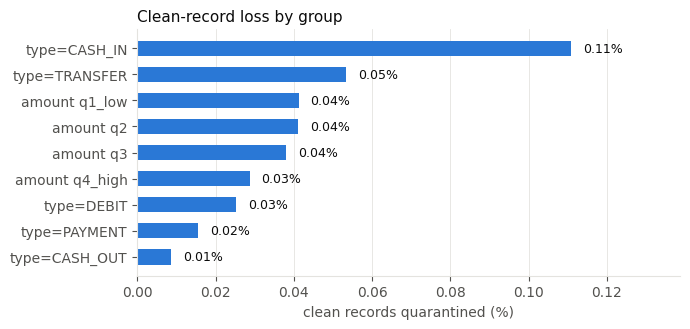

overall clean-record loss: mean 0.037%, max 0.045%


In [5]:
cols = [c for c in det.columns if c.startswith("loss_type=") or c.startswith("loss_amount_bucket=")]
g = det[cols].mean().rename(lambda c: c.replace("loss_", "").replace("amount_bucket=", "amount ")).sort_values()
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh(g.index, g.values * 100, color=BLUE, height=0.6)
for i, v in enumerate(g.values * 100):
    ax.text(v + 0.003, i, f"{v:.2f}%", va="center", color=INK, fontsize=9)
ax.set_xlabel("clean records quarantined (%)"); ax.set_xlim(0, max(g.values * 100) * 1.25)
ax.set_title("Clean-record loss by group", loc="left", color=INK, fontsize=11); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print("overall clean-record loss: mean %.3f%%, max %.3f%%" % (det.clean_loss.mean() * 100, det.clean_loss.max() * 100))

## 4. Detection quality per attack

`recall` and `precision` are measured against the poisoned records; `clean_loss` is the share of clean records
quarantined; `real_frauds_lost` is the share of true (unpoisoned) frauds quarantined, which hurts the learner most;
`time_to_detect` is in windows from the first poisoned window.

In [6]:
t = det.groupby("attack").agg(recall=("recall", "mean"), precision=("precision", "mean"), clean_loss=("clean_loss", "max"),
                             real_frauds_lost=("clean_fraud_loss", "mean"), time_to_detect=("time_to_detect", "mean"),
                             poisoned_rows=("n_poisoned", "mean")).round(4)
t

,recall,precision,clean_loss,real_frauds_lost,time_to_detect,poisoned_rows
attack,,,,,,
backdoor,0.6136,0.1543,0.0004,0.0659,0.0000,79.0
feature_noise,0.8976,0.2209,0.0004,0.0520,0.0000,79.0
feature_scale,0.0277,0.0116,0.0004,0.0615,7.3333,79.0
feature_shift,1.0000,0.2337,0.0004,0.0659,0.0000,79.0
random_flip,0.9466,0.9953,0.0005,0.0284,0.0000,71059.5
targeted_flip,0.9952,0.2121,0.0004,0.0566,0.0000,69.6


## Limitations (read before quoting a number)

- **One seed.** Seeds 1 and 2 are pending; differences of a few hundredths are within noise.
- **`feature_scale` is nearly undetectable** (recall about 0.03). Multiplying amount and balances by 5 keeps the
  balance identity intact, so the rows look like larger transactions. It barely hurts the learner (PR-AUC 0.998).
- **Backdoor recall is about 0.6**, and the learner is barely affected by this backdoor trigger either.
- **Thresholds were tuned on the same samples** (seed 0), so these results are optimistic. In particular
  `alarm_tighten` (1.5 here; 4 gave a higher PR-AUC but unstable recall at the 0.5 cutoff) and `maha_threshold` (3).
- **Window 0 is trusted** (assumed clean). An attacker who poisons it defeats the references.
- **Fraud rows in window 0 and 1 are judged late**: window 0 has about 24 frauds, so fraud-class checks start at window 1.
- **Recall at the fixed 0.5 cutoff is noisy** (it swung between 0.5 and 0.98 across nearby settings); PR-AUC is the headline.
- PaySim fraud is easy to separate (clean PR-AUC 0.999), so absolute utility numbers are optimistic for harder data.
